# Data Preprocessing

## Contents

1. Understanding the data
2. Removing unnecessary data
3. Missing values
4. Outliers
5. Standardization and normalization
6. Encoding categorical variables
7. Revision

## Dataset

[Salary dataset](https://github.com/BouhamedMohammedMounir/Machine-learning-course/blob/master/salaries.csv)

The dataset was adapted for preprocessing exercises by adding missing values,
duplicate rows and extreme salaries. The examples use `salary_in_usd` to
compare salaries in the same currency.

Enable Internet access and run the cells in order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OrdinalEncoder

pd.set_option("display.max_columns", None)

### Load the dataset

In [2]:
source_url = (
    "https://raw.githubusercontent.com/"
    "BouhamedMohammedMounir/Machine-learning-course/"
    "master/salaries.csv"
)

data = pd.read_csv(source_url)
raw_data = data.copy()

print("Shape:", data.shape)
data.head()

Shape: (152959, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025.0,EX,FT,Head of Data,348516.0,USD,NaN,US,0.0,US,M
1,2025.0,EX,FT,Head of Data,232344.0,USD,232344.0,US,0.0,NaN,M
2,2025.0,SE,NaN,Data Scientist,145400.0,USD,145400.0,US,NaN,NaN,M
3,2025.0,SE,FT,Data Scientist,81600.0,NaN,81600.0,US,0.0,NaN,M
4,2025.0,MI,FT,Engineer,160000.0,USD,160000.0,US,100.0,US,M


## 1. Understanding the data

In [3]:
data.shape

(152959, 11)

In [4]:
data.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')

In [5]:
data.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025.0,EX,FT,Head of Data,348516.0,USD,NaN,US,0.0,US,M
1,2025.0,EX,FT,Head of Data,232344.0,USD,232344.0,US,0.0,NaN,M
2,2025.0,SE,NaN,Data Scientist,145400.0,USD,145400.0,US,NaN,NaN,M
3,2025.0,SE,FT,Data Scientist,81600.0,NaN,81600.0,US,0.0,NaN,M
4,2025.0,MI,FT,Engineer,160000.0,USD,160000.0,US,100.0,US,M


In [6]:
data.tail()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
152954,2023.0,SE,FT,Machine Learning Engineer,134500.0,USD,134500.0,US,0.0,NaN,L
152955,2025.0,EN,PT,Software Engineer,40000.0,USD,40000.0,US,0.0,NaN,M
152956,2024.0,MI,FT,Data Management Analyst,76050.0,USD,76050.0,US,100.0,US,M
152957,NaN,SE,FT,Associate,82300.0,NaN,NaN,CA,0.0,NaN,M
152958,2025.0,MI,FT,Data Scientist,85000.0,USD,85000.0,US,0.0,NaN,M


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152959 entries, 0 to 152958
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   work_year           149900 non-null  float64
 1   experience_level    145306 non-null  object 
 2   employment_type     146844 non-null  object 
 3   job_title           146841 non-null  object 
 4   salary              143789 non-null  float64
 5   salary_currency     148377 non-null  object 
 6   salary_in_usd       140708 non-null  float64
 7   employee_residence  146846 non-null  object 
 8   remote_ratio        145318 non-null  float64
 9   company_location    22937 non-null   object 
 10  company_size        145319 non-null  object 
dtypes: float64(4), object(7)
memory usage: 12.8+ MB


In [8]:
data.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,149900.000000,1.437890e+05,1.407080e+05,145318.000000
mean,2024.434923,2.029133e+05,1.985864e+05,20.966088
std,0.671743,4.564148e+05,4.169895e+05,40.640179
min,2020.000000,1.400000e+04,1.500000e+04,0.000000
25%,2024.000000,1.063000e+05,1.062000e+05,0.000000
50%,2025.000000,1.480000e+05,1.477200e+05,0.000000
75%,2025.000000,2.000000e+05,2.000000e+05,0.000000
max,2025.000000,3.040000e+07,5.939071e+06,100.000000


In [9]:
data.describe(include="object")

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size
count,145306,146844,146841,148377,146846,22937,145319
unique,4,4,422,26,104,97,3
top,SE,FT,Data Scientist,USD,US,US,M
freq,83884,145971,18180,140272,131398,20406,141370


### Unique values in categorical columns

In [10]:
categorical_columns = data.select_dtypes(include="object").columns

for column in categorical_columns:
    print(column, ":", data[column].nunique(), "unique values")

experience_level : 4 unique values
employment_type : 4 unique values
job_title : 422 unique values
salary_currency : 26 unique values
employee_residence : 104 unique values
company_location : 97 unique values
company_size : 3 unique values


## 2. Removing unnecessary data

### Duplicate rows

Find exact duplicate rows, then remove them.

In [11]:
data.duplicated().sum()

np.int64(43184)

In [12]:
rows_before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", rows_before - len(data))
data.shape

Duplicate rows removed: 43184


(109775, 11)

### Missing values

In [13]:
missing_values = data.isnull().sum()

missing_table = pd.DataFrame({
    "Missing values": missing_values,
    "Percentage": missing_values / len(data) * 100
})

missing_table.sort_values("Percentage", ascending=False).round(2)

,Missing values,Percentage
company_location,89906,81.90
salary_in_usd,10896,9.93
salary,8295,7.56
company_size,7187,6.55
remote_ratio,7060,6.43
experience_level,6984,6.36
employment_type,5801,5.28
employee_residence,5777,5.26
job_title,5004,4.56
salary_currency,4387,4.00


Remove columns with **70% or more** missing values.

In [14]:
missing_threshold = 70
columns_to_remove = missing_table[
    missing_table["Percentage"] >= missing_threshold
].index.tolist()

columns_to_remove

['company_location']

In [15]:
data = data.drop(columns=columns_to_remove)
print("Columns removed:", columns_to_remove)
data.shape

Columns removed: ['company_location']


(109775, 10)

### Rows with missing values

Compare removing every incomplete row with removing only rows that lack
`salary_in_usd`. Store the results in separate copies so that `data` still
contains missing values for the imputation examples.

For a salary prediction task, remove rows with a missing target rather
than imputing the target value.

In [16]:
complete_rows = data.dropna()
salary_rows = data.dropna(subset=["salary_in_usd"])

row_removal_comparison = pd.DataFrame({
    "Rows kept": [len(data), len(complete_rows), len(salary_rows)],
    "Rows removed": [0, len(data) - len(complete_rows), len(data) - len(salary_rows)]
}, index=[
    "Before row removal",
    "Remove every incomplete row",
    "Remove rows missing salary_in_usd"
])
row_removal_comparison

,Rows kept,Rows removed
Before row removal,109775,0
Remove every incomplete row,57833,51942
Remove rows missing salary_in_usd,98879,10896


## 3. Handling missing values

In [17]:
data.isnull().sum()

,0
work_year,2906
experience_level,6984
employment_type,5801
job_title,5004
salary,8295
salary_currency,4387
salary_in_usd,10896
employee_residence,5777
remote_ratio,7060
company_size,7187


### Numerical variables

Mean:

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

The median is less sensitive to extreme values.

In [18]:
numeric_columns = data.select_dtypes(include=np.number).columns
numeric_columns

Index(['work_year', 'salary', 'salary_in_usd', 'remote_ratio'], dtype='object')

#### Mean imputation

Use a copy of the data to compare mean and median imputation.

In [19]:
mean_example = data.copy()

for column in mean_example.select_dtypes(include=np.number).columns:
    mean_example[column] = mean_example[column].fillna(
        mean_example[column].mean()
    )

imputation_comparison = pd.DataFrame({
    "Missing before": data[numeric_columns].isnull().sum(),
    "Mean": data[numeric_columns].mean(),
    "Median": data[numeric_columns].median(),
    "Missing after imputation": mean_example[numeric_columns].isnull().sum(),
})
imputation_comparison

,Missing before,Mean,Median,Missing after imputation
work_year,2906,2024.427112,2025.0,0
salary,8295,218546.885258,144600.0,0
salary_in_usd,10896,212955.232466,144000.0,0
remote_ratio,7060,22.443168,0.0,0


#### Median imputation

In [20]:
numerical_missing_before = data[numeric_columns].isnull().sum()

for column in numeric_columns:
    data[column] = data[column].fillna(data[column].median())

pd.DataFrame({
    "Missing before": numerical_missing_before,
    "Missing after": data[numeric_columns].isnull().sum()
})

,Missing before,Missing after
work_year,2906,0
salary,8295,0
salary_in_usd,10896,0
remote_ratio,7060,0


### Categorical variables

Replace missing values with the mode, the most frequent category.

In [21]:
categorical_columns = data.select_dtypes(include="object").columns
categorical_missing_before = data[categorical_columns].isnull().sum()

for column in categorical_columns:
    if data[column].isnull().any():
        data[column] = data[column].fillna(data[column].mode()[0])

pd.DataFrame({
    "Missing before": categorical_missing_before,
    "Missing after": data[categorical_columns].isnull().sum()
})

,Missing before,Missing after
experience_level,6984,0
employment_type,5801,0
job_title,5004,0
salary_currency,4387,0
employee_residence,5777,0
company_size,7187,0


## 4. Outlier detection and treatment

### Interquartile range

$$
\mathrm{IQR} = Q_3 - Q_1
$$

Flag values outside these limits:

$$
L = Q_1 - 1.5\,\mathrm{IQR}, \qquad U = Q_3 + 1.5\,\mathrm{IQR}
$$

Use `salary_in_usd` because `salary` contains amounts in different currencies.

In [22]:
outlier_columns = ["salary_in_usd"]

Q1 = data[outlier_columns].quantile(0.25)
Q3 = data[outlier_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower bound": lower_bound,
    "Upper bound": upper_bound,
})

,Q1,Q3,IQR,Lower bound,Upper bound
salary_in_usd,106371.0,190000.0,83629.0,-19072.5,315443.5


In [23]:
outlier_count = {}

for column in outlier_columns:
    condition = (
        (data[column] < lower_bound[column]) |
        (data[column] > upper_bound[column])
    )
    outlier_count[column] = condition.sum()

pd.Series(outlier_count, name="Outliers")

,Outliers
salary_in_usd,4493


### Box plot

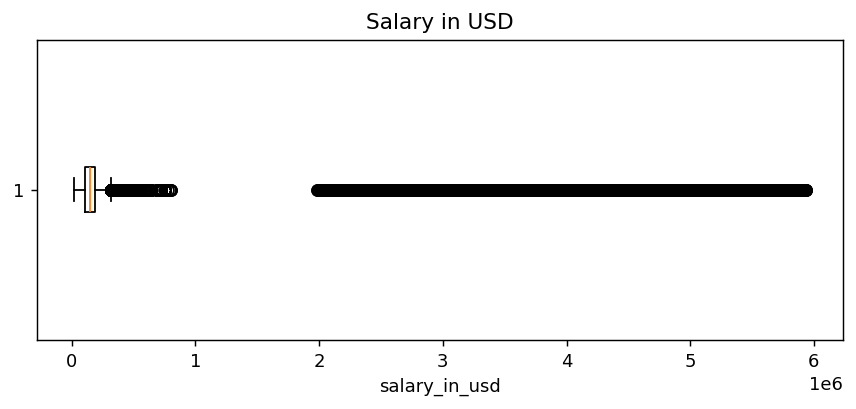

In [24]:
plt.figure(figsize=(8, 3))
plt.boxplot(data["salary_in_usd"], vert=False)
plt.xlabel("salary_in_usd")
plt.title("Salary in USD")
plt.show()

Cap `salary_in_usd` at the IQR limits. Review flagged values before applying
capping to a real dataset, since some extreme salaries may be valid.

In [25]:
salary_q1 = data["salary_in_usd"].quantile(0.25)
salary_q3 = data["salary_in_usd"].quantile(0.75)
salary_iqr = salary_q3 - salary_q1

salary_lower = salary_q1 - 1.5 * salary_iqr
salary_upper = salary_q3 + 1.5 * salary_iqr

data_capped = data.copy()
data_capped["salary_in_usd"] = data_capped["salary_in_usd"].clip(
    lower=salary_lower,
    upper=salary_upper
)

outside_before = (
    (data["salary_in_usd"] < salary_lower) |
    (data["salary_in_usd"] > salary_upper)
).sum()
outside_after = (
    (data_capped["salary_in_usd"] < salary_lower) |
    (data_capped["salary_in_usd"] > salary_upper)
).sum()
print("Outliers before capping:", outside_before)
print("Outliers after capping:", outside_after)
data_capped["salary_in_usd"].describe()

Outliers before capping: 4493
Outliers after capping: 0


,salary_in_usd
count,109775.000000
mean,153887.623498
std,67305.427093
min,15000.000000
25%,106371.000000
50%,144000.000000
75%,190000.000000
max,315443.500000


## 5. Standardization and normalization

### Standardization

$$
z = \frac{x - \mu}{\sigma}
$$

For prediction tasks, fit preprocessing on the training data and use the same
parameters for the test data. Exclude `salary_in_usd` and `salary` from the
input features if `salary_in_usd` is the prediction target.

In [26]:
numeric_columns = data_capped.select_dtypes(include=np.number).columns

standard_scaler = StandardScaler()

standardized_data = data_capped.copy()
standardized_data[numeric_columns] = standard_scaler.fit_transform(
    data_capped[numeric_columns]
)

standardized_data[numeric_columns].head()

,work_year,salary,salary_in_usd,remote_ratio
0,0.806244,0.262075,-0.146907,-0.516681
1,0.806244,0.037477,1.165682,-0.516681
2,0.806244,-0.130613,-0.126107,-0.516681
3,0.806244,-0.253959,-1.074029,-0.516681
4,0.806244,-0.102387,0.090816,1.943730


### Min-max normalization

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

In [27]:
minmax_scaler = MinMaxScaler()

normalized_data = data_capped.copy()
normalized_data[numeric_columns] = minmax_scaler.fit_transform(
    data_capped[numeric_columns]
)

normalized_data[numeric_columns].head()

,work_year,salary,salary_in_usd,remote_ratio
0,1.0,0.011009,0.429365,0.0
1,1.0,0.007186,0.723411,0.0
2,1.0,0.004324,0.434025,0.0
3,1.0,0.002225,0.221672,0.0
4,1.0,0.004805,0.482620,1.0


## 6. Encoding categorical variables

### Label encoding

Assign an integer to each job title. These codes identify categories and do
not imply a ranking.

In [28]:
label_encoder = LabelEncoder()

job_title_encoded = data_capped[["job_title"]].copy()
job_title_encoded["job_title_code"] = label_encoder.fit_transform(
    job_title_encoded["job_title"]
)

job_title_encoded.drop_duplicates().head(10)

,job_title,job_title_code
0,Head of Data,262
2,Data Scientist,202
4,Engineer,245
6,AI Product Lead,12
8,AI Engineer,5
10,Business Intelligence Engineer,89
12,Manager,301
17,Computer Vision Engineer,111
23,Data Management,164
25,Product Manager,344


### Ordinal encoding

Encode experience levels in this order:

$\mathrm{EN} < \mathrm{MI} < \mathrm{SE} < \mathrm{EX}$

In [29]:
ordinal_encoder = OrdinalEncoder(
    categories=[["EN", "MI", "SE", "EX"]]
)

experience_encoded = data_capped[["experience_level"]].copy()
experience_encoded["experience_code"] = ordinal_encoder.fit_transform(
    experience_encoded[["experience_level"]]
)

experience_encoded.drop_duplicates().sort_values("experience_code").reset_index(drop=True)

,experience_level,experience_code
0,EN,0.0
1,MI,1.0
2,SE,2.0
3,EX,3.0


### One-hot encoding

Create a binary column for each employment type.

In [30]:
employment_encoded = pd.get_dummies(
    data_capped["employment_type"],
    prefix="employment",
    dtype=int
)

employment_examples = pd.concat(
    [data_capped[["employment_type"]], employment_encoded], axis=1
)
employment_examples = (
    employment_examples.drop_duplicates()
    .sort_values("employment_type")
    .reset_index(drop=True)
)
employment_examples

,employment_type,employment_CT,employment_FL,employment_FT,employment_PT
0,CT,1,0,0,0
1,FL,0,1,0,0
2,FT,0,0,1,0
3,PT,0,0,0,1


Join the encoded columns to the DataFrame.

In [31]:
encoded_data = pd.concat(
    [
        data_capped.drop(columns=["employment_type"]),
        employment_encoded
    ],
    axis=1
)

encoded_data.head()

,work_year,experience_level,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_size,employment_CT,employment_FL,employment_FT,employment_PT
0,2025.0,EX,Head of Data,348516.0,USD,144000.0,US,0.0,M,0,0,1,0
1,2025.0,EX,Head of Data,232344.0,USD,232344.0,US,0.0,M,0,0,1,0
2,2025.0,SE,Data Scientist,145400.0,USD,145400.0,US,0.0,M,0,0,1,0
3,2025.0,SE,Data Scientist,81600.0,USD,81600.0,US,0.0,M,0,0,1,0
4,2025.0,MI,Engineer,160000.0,USD,160000.0,US,100.0,M,0,0,1,0


## 7. Revision

1. Show the dimensions.
2. Display the first five rows.
3. Identify duplicated rows.
4. Remove duplicates.
5. Calculate missing-value percentages.
6. Remove columns with at least 70% missing values.
7. Compare the two row-deletion methods using separate copies.
8. Fill numerical missing values with the median.
9. Fill categorical missing values with the mode.
10. Detect salary outliers using IQR.
11. Cap salary values using those limits.
12. Standardize numerical variables.
13. One-hot encode `employment_type`.

### Solution

In [32]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

revision = pd.read_csv(
    "https://raw.githubusercontent.com/"
    "BouhamedMohammedMounir/Machine-learning-course/master/salaries.csv"
)
print("Shape:", revision.shape)
print(revision.head())
print("Duplicated rows:", revision.duplicated().sum())
revision = revision.drop_duplicates().reset_index(drop=True)

missing_percentage = revision.isnull().mean() * 100
print("Missing-value percentages:")
print(missing_percentage.sort_values(ascending=False))
missing_threshold = 70
revision_columns_to_remove = missing_percentage[missing_percentage >= missing_threshold].index
revision = revision.drop(columns=revision_columns_to_remove)

complete_revision = revision.dropna()
salary_revision = revision.dropna(subset=["salary_in_usd"])
print("Rows after removing every incomplete row:", len(complete_revision))
print("Rows after removing missing USD salaries:", len(salary_revision))

num_cols = revision.select_dtypes(include=np.number).columns
cat_cols = revision.select_dtypes(include="object").columns

for col in num_cols:
    revision[col] = revision[col].fillna(revision[col].median())

for col in cat_cols:
    if revision[col].isnull().any():
        revision[col] = revision[col].fillna(revision[col].mode()[0])

q1 = revision["salary_in_usd"].quantile(0.25)
q3 = revision["salary_in_usd"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

salary_outliers = revision[
    (revision["salary_in_usd"] < lower) |
    (revision["salary_in_usd"] > upper)
]
print("Salary outliers before capping:", len(salary_outliers))
revision["salary_in_usd"] = revision["salary_in_usd"].clip(lower, upper)

revision[num_cols] = StandardScaler().fit_transform(revision[num_cols])
revision = pd.get_dummies(revision, columns=["employment_type"], dtype=int)
print("Remaining missing values:", int(revision.isnull().sum().sum()))
revision.head()

Shape: (152959, 11)
   work_year experience_level employment_type       job_title    salary  \
0     2025.0               EX              FT    Head of Data  348516.0   
1     2025.0               EX              FT    Head of Data  232344.0   
2     2025.0               SE             NaN  Data Scientist  145400.0   
3     2025.0               SE              FT  Data Scientist   81600.0   
4     2025.0               MI              FT        Engineer  160000.0   

  salary_currency  salary_in_usd employee_residence  remote_ratio  \
0             USD            NaN                 US           0.0   
1             USD       232344.0                 US           0.0   
2             USD       145400.0                 US           NaN   
3             NaN        81600.0                 US           0.0   
4             USD       160000.0                 US         100.0   

  company_location company_size  
0               US            M  
1              NaN            M  
2           

,work_year,experience_level,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_size,employment_type_CT,employment_type_FL,employment_type_FT,employment_type_PT
0,0.806244,EX,Head of Data,0.262075,USD,-0.146907,US,-0.516681,M,0,0,1,0
1,0.806244,EX,Head of Data,0.037477,USD,1.165682,US,-0.516681,M,0,0,1,0
2,0.806244,SE,Data Scientist,-0.130613,USD,-0.126107,US,-0.516681,M,0,0,1,0
3,0.806244,SE,Data Scientist,-0.253959,USD,-1.074029,US,-0.516681,M,0,0,1,0
4,0.806244,MI,Engineer,-0.102387,USD,0.090816,US,1.943730,M,0,0,1,0


## Summary

- Inspect the data.
- Remove duplicate rows and very incomplete columns.
- Compare deleting incomplete rows with imputing missing values.
- Impute numerical and categorical missing values.
- Detect and treat outliers.
- Standardize or normalize numerical variables.
- Encode categorical variables.

## References

- [Course dataset](https://github.com/BouhamedMohammedMounir/Machine-learning-course/blob/master/salaries.csv)
- [aijobs.net salary dataset](https://github.com/foorilla/ai-jobs-net-salaries), CC0-1.0.